In [60]:
!pip install pyTMD timescale xarray
import numpy as np
import pyTMD
import timescale
import xarray as xr
import matplotlib.pyplot as plt



In [61]:
# 1. Tidal constants (amplitudes in m, phases in degrees, Greenwich/UTC phases)
constituents_list = ["O1", "K1"]
amplitudes = [0.167, 0.157]
phases = [21.2, 35.8]

# 2. Package constants into an xarray Dataset for pyTMD: amp * exp(-i*phase)
# (same for every year, so build it once outside the loop)
hc = np.asarray(amplitudes) * np.exp(-1j * np.radians(phases))
ds = xr.Dataset(
    {c.lower(): ((), hc[k], {"units": "m"}) for k, c in enumerate(constituents_list)}
)

# 3-5. Predict Aug-Nov for 30 years (2026-2055), every 10 min, in LOCAL time
# Local time = fixed UTC-6 (Yucatan, no daylight saving since Oct 2022).
# "Etc/GMT+6" means UTC-6 (the sign is reversed in these zone names).
import pandas as pd

LOCAL_TZ = "Etc/GMT+6"


def predict_tide(times_local):
    """Tide height (m) at the given naive local times."""
    times_utc = times_local.tz_localize(LOCAL_TZ).tz_convert("UTC").tz_localize(None)
    ts = timescale.time.Timescale.from_datetime(times_utc.values)
    h = pyTMD.predict.time_series(ts.tide, ds, deltat=ts.tt_ut1, corrections="OTIS")
    h = h + pyTMD.predict.infer_minor(ts.tide, ds, deltat=ts.tt_ut1, corrections="OTIS")
    return np.asarray(h)


tpred = {}  # tpred[year] -> pandas Series of tide height (m), indexed by LOCAL datetime
for i in range(30):
    year = 2026 + i
    times = pd.date_range(f"{year}-08-01 00:00", f"{year}-11-30 23:50", freq="10min")
    tpred[year] = pd.Series(predict_tide(times), index=times, name="tide_m")

# Example: show the first rows as "YYYY-MM-DD HH:MM" (local time)
print(tpred[2026].head().to_string(index=True, float_format="%.3f"))

2026-08-01 00:00:00   -0.111
2026-08-01 00:10:00   -0.109
2026-08-01 00:20:00   -0.107
2026-08-01 00:30:00   -0.105
2026-08-01 00:40:00   -0.102
Freq: 10min


time   n_days  rising%  falling%  above%  below%
05:30    3660     20.3      79.7    65.9    34.1
06:00    3660     18.3      81.7    62.3    37.7
06:30    3660     16.8      83.2    58.4    41.6
07:00    3660     16.0      84.0    54.6    45.4
07:30    3660     15.6      84.4    50.6    49.4
08:00    3660     15.9      84.1    46.7    53.3
08:30    3660     16.4      83.6    43.0    57.0
09:00    3660     17.7      82.3    38.9    61.1
09:30    3660     19.6      80.4    35.4    64.6
10:00    3660     22.0      78.0    32.0    68.0
10:30    3660     24.9      75.1    28.8    71.2
11:00    3660     28.3      71.7    26.0    74.0
11:30    3660     32.2      67.8    23.5    76.5
12:00    3660     36.3      63.7    21.9    78.1
12:30    3660     40.4      59.6    20.7    79.3
13:00    3660     44.8      55.2    19.9    80.1
13:30    3660     49.3      50.7    19.8    80.2
14:00    3660     53.7      46.3    19.9    80.1
14:30    3660     58.1      41.9    20.5    79.5
15:00    3660     62

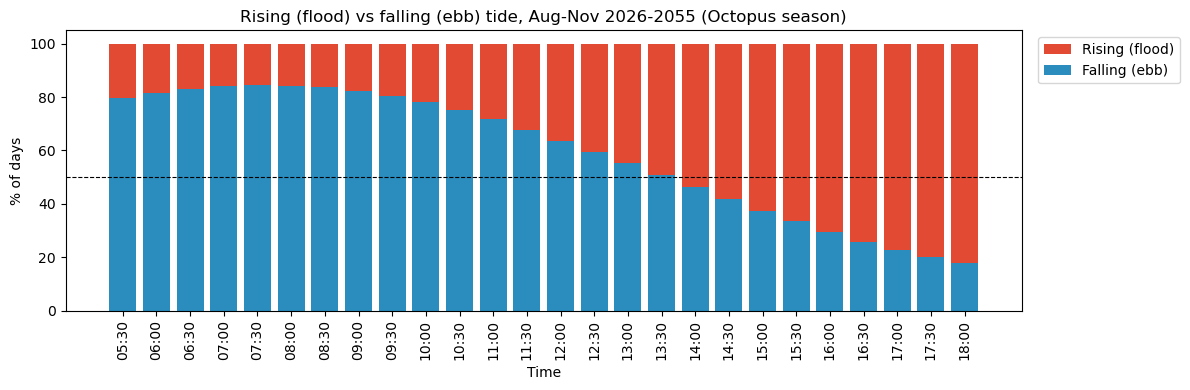

In [62]:
# For each time of day between 05:30 and 18:00 (local time, UTC-6), count over all days
# (Aug-Nov, 2026-2055) how often the tide is:
#   - rising (flood) or falling (ebb)
#   - above or below mean sea level (0 m)

# 1. Make the list of times: "05:30", "06:00", "06:30", ..., "18:00"
time_steps = []
minutes = 5 * 60 + 30            # 05:30 written in minutes
while minutes <= 18 * 60:        # stop at 18:00
    hour = minutes // 60
    minute = minutes % 60
    time_steps.append(f"{hour:02d}:{minute:02d}")
    minutes = minutes + 30

# 2. Start a counter at 0 for every time
n_days = {}
n_rising = {}
n_above = {}
for t in time_steps:
    n_days[t] = 0
    n_rising[t] = 0
    n_above[t] = 0

# 3. Go through every year and every data point
for year in tpred:
    heights = tpred[year].values
    times = tpred[year].index

    # skip the first and last point (they have no neighbour on one side)
    for i in range(1, len(heights) - 1):
        t = times[i].strftime("%H:%M")
        if t not in n_days:
            continue                      # not a time we care about

        n_days[t] = n_days[t] + 1

        # rising if the next value is higher than the previous one
        if heights[i + 1] > heights[i - 1]:
            n_rising[t] = n_rising[t] + 1

        # above mean sea level if height > 0
        if heights[i] > 0:
            n_above[t] = n_above[t] + 1

# 4. Turn the counts into percentages and print a table
rising_pct = []
falling_pct = []
print("time   n_days  rising%  falling%  above%  below%")
for t in time_steps:
    rise = 100 * n_rising[t] / n_days[t]
    above = 100 * n_above[t] / n_days[t]
    rising_pct.append(rise)
    falling_pct.append(100 - rise)
    print(f"{t}  {n_days[t]:6d}  {rise:7.1f}  {100 - rise:8.1f}  {above:6.1f}  {100 - above:6.1f}")

# 5. Bar chart: blue = falling at the bottom, red = rising stacked on top
plt.figure(figsize=(12, 4))
plt.bar(time_steps, falling_pct, color="#2b8cbe", label="Falling (ebb)")
plt.bar(time_steps, rising_pct, bottom=falling_pct, color="#e34a33", label="Rising (flood)")
plt.axhline(50, color="k", lw=0.8, ls="--")
plt.xticks(rotation=90)
plt.ylabel("% of days")
plt.xlabel("Time")
plt.title("Rising (flood) vs falling (ebb) tide, Aug-Nov 2026-2055 (Octopus season)")
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles[::-1], labels[::-1], loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()


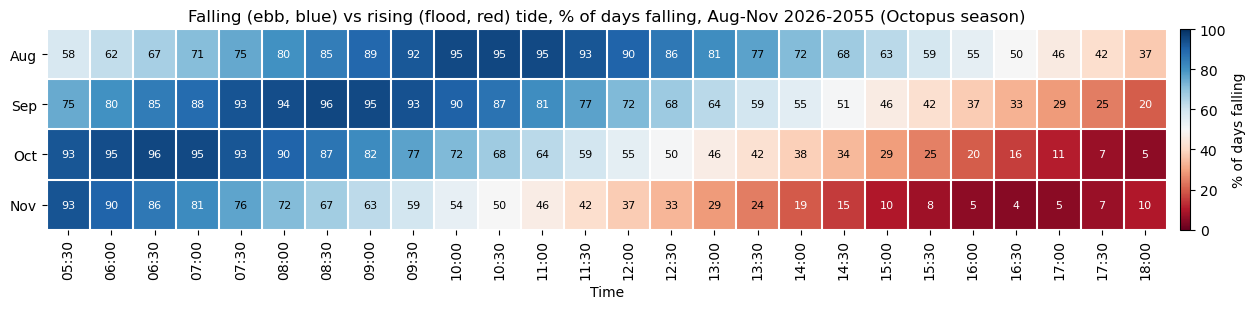

In [63]:
# Heatmap: % of days the tide is FALLING (ebb), per month and time of day (local time)
# Same rule as the table above: falling = next value is not higher than the previous one
import calendar

# 1. Put all years in one table with columns: month, time, falling (True/False)
rows = []
for year in tpred:
    s = tpred[year]
    falling = ~(s.shift(-1) > s.shift(1))             # not rising
    valid = s.shift(-1).notna() & s.shift(1).notna()  # drop first/last point
    rows.append(pd.DataFrame({
        "month": s.index.month[valid],
        "time": s.index.strftime("%H:%M")[valid],
        "falling": falling[valid].values,
    }))
df = pd.concat(rows)
df = df[df["time"].isin(time_steps)]                  # 05:30 ... 18:00 only

# 2. % falling for every (month, time) pair -> rows = months, columns = times
falling_pct_month = df.pivot_table(index="month", columns="time", values="falling",
                                   aggfunc="mean") * 100
falling_pct_month = falling_pct_month[time_steps]     # keep times in order
month_labels = [calendar.month_abbr[m] for m in falling_pct_month.index]

# 3. Draw the heatmap: blue = mostly falling, red = mostly rising, white = 50/50
fig, ax = plt.subplots(figsize=(14, 3.2))
im = ax.imshow(falling_pct_month.values, cmap="RdBu", vmin=0, vmax=100, aspect="auto")

ax.set_xticks(range(len(time_steps)))
ax.set_xticklabels(time_steps, rotation=90)
ax.set_yticks(range(len(month_labels)))
ax.set_yticklabels(month_labels)
ax.set_xlabel("Time")
ax.set_title("Falling (ebb, blue) vs rising (flood, red) tide, % of days falling, Aug-Nov 2026-2055 (Octopus season)")

# write the % in each cell (white text on dark cells, black on light ones)
# (colour shows the % FALLING; rising = 100 - that number)
for r in range(falling_pct_month.shape[0]):
    for c in range(falling_pct_month.shape[1]):
        v = falling_pct_month.values[r, c]
        ax.text(c, r, f"{v:.0f}", ha="center", va="center", fontsize=8,
                color="white" if (v > 80 or v < 20) else "black")

# thin white lines between cells
ax.set_xticks(np.arange(-0.5, len(time_steps)), minor=True)
ax.set_yticks(np.arange(-0.5, len(month_labels)), minor=True)
ax.grid(which="minor", color="white", lw=1.5)
ax.tick_params(which="minor", length=0)
for spine in ax.spines.values():
    spine.set_visible(False)

fig.colorbar(im, ax=ax, label="% of days falling", pad=0.01)
plt.tight_layout()
plt.show()

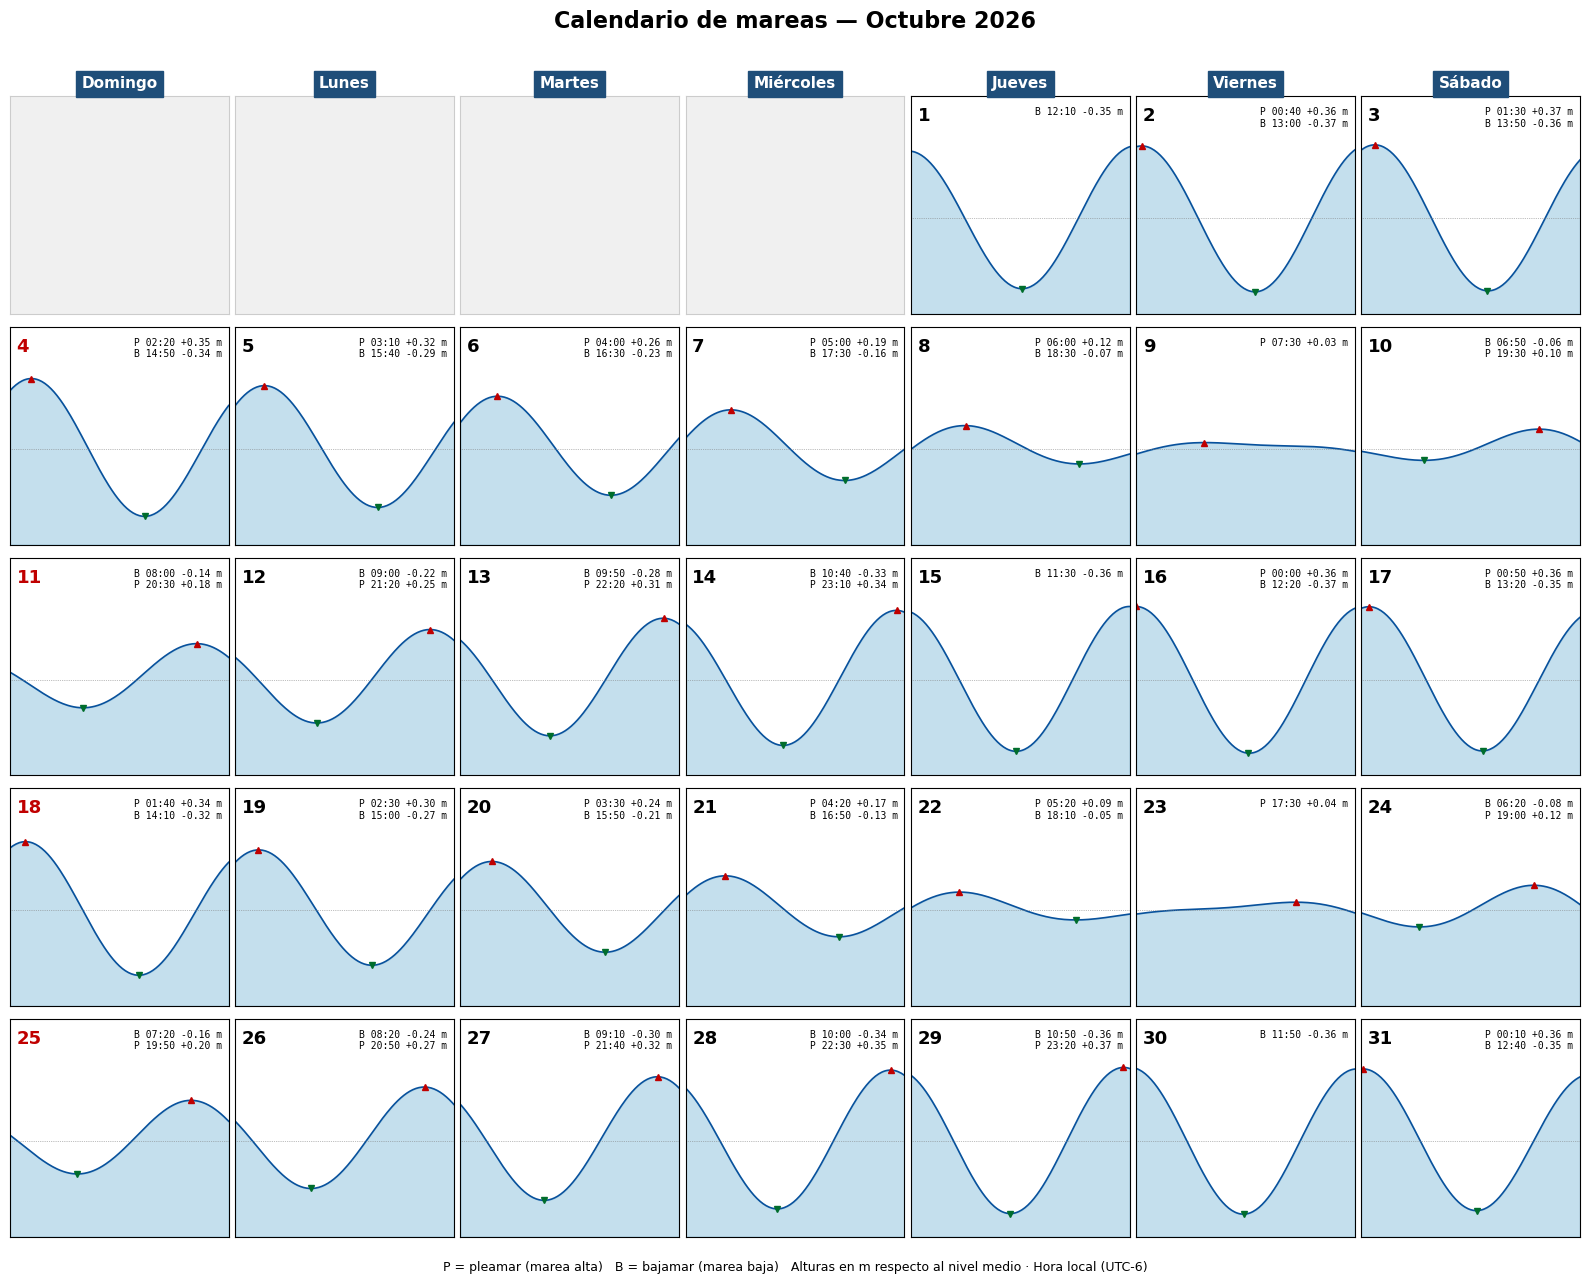

In [64]:
import calendar
import pandas as pd
import matplotlib.dates as mdates

year, month = 2026, 10
month_names_es = ["", "Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio", "Julio",
                  "Agosto", "Septiembre", "Octubre", "Noviembre", "Diciembre"]
weekdays_es = ["Domingo", "Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado"]

# Predict every 10 min so the high/low times are accurate
start = pd.Timestamp(year, month, 1)
end = start + pd.offsets.MonthBegin(1)
times = pd.date_range(start, end, freq="10min")
h = predict_tide(times)  # times are local (UTC-6)

# Highs and lows = local maxima / minima
d = np.diff(h)
i_high = np.where((d[:-1] > 0) & (d[1:] <= 0))[0] + 1
i_low = np.where((d[:-1] < 0) & (d[1:] >= 0))[0] + 1
extremes = sorted([(i, "P") for i in i_high] + [(i, "B") for i in i_low])  # P = pleamar, B = bajamar

ymin, ymax = h.min(), h.max()
pad = 0.15 * (ymax - ymin)
weeks = calendar.Calendar(firstweekday=6).monthdayscalendar(year, month)

fig, axes = plt.subplots(len(weeks), 7, figsize=(16, 2.4 * len(weeks) + 1), sharey=True)
fig.suptitle(f"Calendario de mareas — {month_names_es[month]} {year}", fontsize=16, weight="bold")

for r, week in enumerate(weeks):
    for c, day in enumerate(week):
        ax = axes[r, c]
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(weekdays_es[c], fontsize=11, weight="bold", color="white",
                         backgroundcolor="#1f4e79", pad=6)
        if day == 0:
            ax.set_facecolor("#f0f0f0")
            for s in ax.spines.values():
                s.set_color("#cccccc")
            continue

        d0 = pd.Timestamp(year, month, day)
        m = (times >= d0) & (times <= d0 + pd.Timedelta(days=1))
        x = (times[m] - d0) / pd.Timedelta(hours=1)
        ax.fill_between(x, ymin - pad, h[m], color="#9ecae1", alpha=0.6)
        ax.plot(x, h[m], color="#08519c", lw=1.2)
        ax.axhline(0, color="gray", lw=0.5, ls=":")
        ax.set_xlim(0, 24)
        ax.set_ylim(ymin - pad, ymax + 2.2 * pad)
        ax.text(0.03, 0.95, str(day), transform=ax.transAxes, fontsize=13, weight="bold",
                va="top", color="#c00000" if c == 0 else "black")

        # high/low labels: time + height, listed in the top-right corner
        lines = []
        for i, kind in extremes:
            if d0 <= times[i] < d0 + pd.Timedelta(days=1):
                hr = (times[i] - d0) / pd.Timedelta(hours=1)
                ax.plot(hr, h[i], "^" if kind == "P" else "v",
                        color="#c00000" if kind == "P" else "#006d2c", ms=4)
                lines.append(f"{kind} {times[i]:%H:%M} {h[i]:+.2f} m")
        ax.text(0.97, 0.95, "\n".join(lines), transform=ax.transAxes, fontsize=7,
                va="top", ha="right", family="monospace")

fig.text(0.5, 0.01, "P = pleamar (marea alta)   B = bajamar (marea baja)   "
         "Alturas en m respecto al nivel medio · Hora local (UTC-6)", ha="center", fontsize=9)
plt.tight_layout(rect=[0, 0.025, 1, 0.97])
plt.subplots_adjust(wspace=0.03, hspace=0.06)
plt.show()


Period: 2020-12-31 to 2027-12-31 (local), n = 61344 hours
Correlation r   = 0.908
RMSE            = 8.8 cm
Std CICESE      = 20.9 cm   Std model = 18.2 cm
Range CICESE    = -0.67 to +0.53 m   model = -0.37 to +0.37 m
Aug-Nov 05-18 h: rising/falling agree 85.4% | above/below MSL agree 84.4%


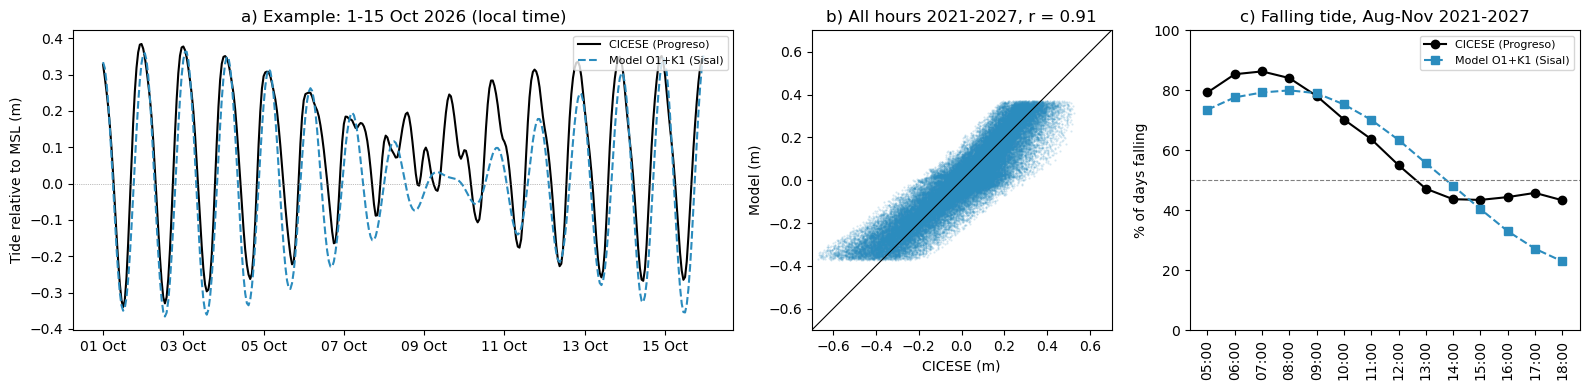

In [65]:
# VALIDATION: compare the O1+K1 model with the CICESE tide prediction (programa MAR)
# for Pto. Progreso, Yuc. (21°17'N, 89°40'W, ~50 km east of Sisal), 2021-2027.
# Source: https://redmar.cicese.mx/meteoro/calendario_tabla/prediccion_con_mar.php
# CICESE file: hourly, UTC, heights in mm above MLLW (Bajamar Media Inferior).
# Note: in the 2021-2023 files negative values <= -100 mm at 00 and 12 UTC were
# printed without the minus sign; these were fixed (column "sign_fixed").

# 1. Load CICESE, convert to metres relative to mean sea level, and to local time
cic = pd.read_csv("CICESE_Progreso_TidePrediction_2021_2027.csv", index_col=0, parse_dates=True)
obs = cic["h_mm"] / 1000
obs = obs - obs.mean()                                 # MLLW -> mean sea level
obs.index = obs.index - pd.Timedelta(hours=6)          # UTC -> local (UTC-6)

# 2. Our model at exactly the same (local) times
mod = pd.Series(predict_tide(obs.index), index=obs.index)

# 3. Overall statistics
err = mod - obs
r = np.corrcoef(obs, mod)[0, 1]
print(f"Period: {obs.index[0]:%Y-%m-%d} to {obs.index[-1]:%Y-%m-%d} (local), n = {len(obs)} hours")
print(f"Correlation r   = {r:.3f}")
print(f"RMSE            = {np.sqrt(np.mean(err**2)) * 100:.1f} cm")
print(f"Std CICESE      = {obs.std() * 100:.1f} cm   Std model = {mod.std() * 100:.1f} cm")
print(f"Range CICESE    = {obs.min():+.2f} to {obs.max():+.2f} m   model = {mod.min():+.2f} to {mod.max():+.2f} m")

# 4. Do they agree on rising/falling and above/below MSL?
#    (same rule as above, but hourly: compare 1 h after with 1 h before)
#    Only the period we use: Aug-Nov, 05:00-18:00 local
rising_obs = obs.shift(-1) > obs.shift(1)
rising_mod = mod.shift(-1) > mod.shift(1)
season = (obs.index.month >= 8) & (obs.index.month <= 11)
daytime = (obs.index.hour >= 5) & (obs.index.hour <= 18)
sel = season & daytime & obs.shift(-1).notna() & obs.shift(1).notna()
agree_rise = (rising_obs[sel] == rising_mod[sel]).mean() * 100
agree_above = ((obs[sel] > 0) == (mod[sel] > 0)).mean() * 100
print(f"Aug-Nov 05-18 h: rising/falling agree {agree_rise:.1f}% | above/below MSL agree {agree_above:.1f}%")

# 5. % of days falling per hour of day (Aug-Nov 2021-2027): CICESE vs model
hours = list(range(5, 19))
fall_obs = [100 * (~rising_obs[sel & (obs.index.hour == h)]).mean() for h in hours]
fall_mod = [100 * (~rising_mod[sel & (obs.index.hour == h)]).mean() for h in hours]
hour_labels = [f"{h:02d}:00" for h in hours]

fig, axes = plt.subplots(1, 3, figsize=(16, 4), gridspec_kw={"width_ratios": [2.2, 1, 1.3]})

# a) example: two weeks of time series
ax = axes[0]
a, b = "2026-10-01", "2026-10-15"
ax.plot(obs[a:b], color="k", lw=1.5, label="CICESE (Progreso)")
ax.plot(mod[a:b], color="#2b8cbe", lw=1.5, ls="--", label="Model O1+K1 (Sisal)")
ax.axhline(0, color="gray", lw=0.5, ls=":")
ax.set_ylabel("Tide relative to MSL (m)")
ax.set_title("a) Example: 1-15 Oct 2026 (local time)")
ax.legend(loc="upper right", fontsize=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))

# b) scatter model vs CICESE, all hours
ax = axes[1]
ax.plot(obs, mod, ".", ms=1, color="#2b8cbe", alpha=0.2)
lim = [-0.7, 0.7]
ax.plot(lim, lim, "k", lw=0.8)
ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
ax.set_xlabel("CICESE (m)"); ax.set_ylabel("Model (m)")
ax.set_title(f"b) All hours 2021-2027, r = {r:.2f}")

# c) % of days falling per hour: CICESE vs model
ax = axes[2]
ax.plot(hour_labels, fall_obs, "o-", color="k", lw=1.5, label="CICESE (Progreso)")
ax.plot(hour_labels, fall_mod, "s--", color="#2b8cbe", lw=1.5, label="Model O1+K1 (Sisal)")
ax.axhline(50, color="gray", lw=0.8, ls="--")
ax.set_ylim(0, 100)
ax.set_ylabel("% of days falling")
ax.set_title("c) Falling tide, Aug-Nov 2021-2027")
ax.tick_params(axis="x", rotation=90)
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()